# Additional Analyses using GOATPY

*Author: [Andrew Causer](https://agc888.github.io/OspreyAI)*

This notebook demonstrates some additional analyses you can perform using *goatpy* such as:
* single cell segmentation and clustering
* spatial auto-correlation analysis

For more infomation on how to run general analysis using *goatpy* please visit the [Getting Started](https://goatpy.readthedocs.io/en/latest/guides/getting_started.html#Loading-and-Aligning-Data) page.


## Single Cell Segmentation

Cell segmentation is a popular analyses performed in any spatial-omics based pipeline, particularly when dealing with non-single cell resolution omic datatype (such as MALDI MSI).

*goatpy* usings the python package SpatialData as a framework to store all relavent data and metadata types. Using SpatialData has many benfits including the use of numerous additional packages that are also build around this framework, such as SOPA. 

[SOPA](https://prism-oncology.github.io/sopa/) is a spatial-omics tool that is designed for running image-based analyses corresponding to various omics datasets. SOPA has many established functionalties, including cell segmentation bassed on IHC or H&E images. We will use SOPA to perform single-cell segmentation on our kidney dataset example below:

### Import Packages and Data

This analysis requires the package [SOPA](https://prism-oncology.github.io/sopa/). There are many handy tutorials on how to use SOPA to analyse image data, inparticular when combined with spatial-omics data. goatpy integrates SOPA functionings to work with MALDI-MSI data.

In [1]:
import goatpy as gp
from spatialdata import read_zarr
import spatialdata_plot
import matplotlib.pyplot as plt
import scanpy as sc
import sopa

/Users/andrewcauser/goatpy/goatpy/io.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


### Using Auto Aligned data
After loading our packages we can load and align our MSI and H&E imaging data together using `gp.load_and_align`. This function automatically aligns the MSI and H&E data and returns an aligned *SpatialData* object.

Lets run the auto alignment below:

In [2]:
sdata = gp.load_and_align(
    imzml_path="/Users/andrewcauser/Documents/Griffith/test_data/IHC_new/ad_dm_sa_deriv_19pm0001_0204002_reduced_peakonly.imzML",
    he_path="/Users/andrewcauser/Documents/he_2x_viewer.ome.tif",
    peaks_path="/Users/andrewcauser/Documents/Griffith/test_data/IHC_new/Sample 19M0001 glycan list.csv",
    coarse_rotation_step=1,
    maldi_pixel_um=50,
    he_pixel_um=0.2738084*2,
    buffer_px=300,
    img_upscaling = 50,
    auto_scale=True,
    scale_range=(0.8, 1.6),
)

[0.71GB] Loading peaks ...
[0.71GB]   174 peaks


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/PIL/TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


[1.31GB]   MALDI pixel size (supplied): 50 um/px
[1.31GB]   maldi_pixel_um=50  ref_pixel_um=0.5476
[1.31GB] Computing MALDI crop offsets ...


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/pyimzml/ontology/ontology.py:92: UserWarning: Accession IMS:1000046 found with incorrect name "pixel size x". Updating name to "pixel size (x)".
  warn(


[1.34GB]   Crop: row=0, col=0
[1.33GB] Loading 174 ion images (chunk=10) with 0.1 Da tolerance per peak ...


/Users/andrewcauser/goatpy/goatpy/io.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/andrewcauser/goatpy/goatpy/io.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/andrewcauser/goatpy/goatpy/io.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/andrewcauser/goatpy/goatpy/io.py:7: UserWarning: pkg_resources is dep

[1.54GB]   Peaks 1-10 / 174
[1.54GB]   Peaks 11-20 / 174
[1.54GB]   Peaks 21-30 / 174
[1.54GB]   Peaks 31-40 / 174
[1.54GB]   Peaks 41-50 / 174
[1.54GB]   Peaks 51-60 / 174
[1.54GB]   Peaks 61-70 / 174
[1.54GB]   Peaks 71-80 / 174
[1.54GB]   Peaks 81-90 / 174
[1.54GB]   Peaks 91-100 / 174
[1.54GB]   Peaks 101-110 / 174
[1.54GB]   Peaks 111-120 / 174
[1.50GB]   Peaks 121-130 / 174
[1.50GB]   Peaks 131-140 / 174
[1.50GB]   Peaks 141-150 / 174
[1.50GB]   Peaks 151-160 / 174
[0.67GB]   Peaks 161-170 / 174
[0.67GB]   Peaks 171-174 / 174
[0.68GB]   spectra_all: (492, 544, 174)  (186 MB)
[0.68GB] Preparing MALDI template ...
[0.68GB]   MALDI grayscale: (492, 544)  mean=0.192
[0.85GB] Loading H&E at 50 um/px ...
[3.05GB]   openslide level 0: 40044x36341  0.548 um/px  (4366 MB)
[0.34GB]   Resized to 439x398  50.000 um/px
[0.34GB]   H&E: 439x398  (1 MB)
[0.34GB] Preparing H&E registration image ...
[0.35GB]   H&E grayscale: (398, 439)  mean=0.183
[0.35GB] Running registration ...
[0.35GB]   Auto

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


[3.95GB]   Transform stored: mode=he  rotation=0.0  ref_reg_size=[496, 547]  canvas_placement=[10, 10]
[3.95GB] Done.


In [4]:
sdata

SpatialData object
├── Images
│     └── 'he_image': DataArray[cyx] (3, 25800, 28350)
├── Points
│     └── 'centroids': DataFrame with shape: (<Delayed>, 3) (2D points)
├── Shapes
│     └── 'pixels': GeoDataFrame shape: (267648, 2) (2D shapes)
└── Tables
      └── 'maldi_adata': AnnData (267648, 174)
with coordinate systems:
    ▸ 'global', with elements:
        he_image (Images), centroids (Points), pixels (Shapes)

Following the alignment we can visualise the results by generating plots overalying the MSI and H&E data:

INFO     Rasterizing image for faster rendering.                                                                   


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     
INFO     Rasterizing image for faster rendering.                                                                   


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


... (3 outputs left out)

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     


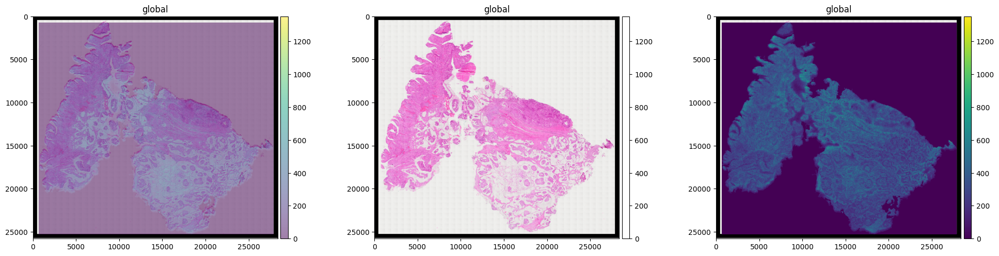

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), dpi=200)

sdata.pl.render_images("he_image") \
     .pl.render_shapes("pixels",size = 3,fill_alpha = 0.5,color="MPI").pl.show(ax=axes[0])

sdata.pl.render_images("he_image") \
     .pl.render_shapes("pixels",size = 3,fill_alpha = 0,color="MPI").pl.show(ax=axes[1])

sdata.pl.render_images("he_image") \
     .pl.render_shapes("pixels",size = 3,fill_alpha = 1,color="MPI").pl.show(ax=axes[2])

plt.tight_layout()
plt.show()

During automatic alignment, the H&E image is often downscaled and stretched to match the spatial dimensions of the MALDI data. This is generally sufficient for whole-slide visualisation, such as plotting the tissue alongside pathologist annotations, where high image resolution is not essential. In fact, retaining unnecessarily high-resolution images can substantially increase memory usage and slow down visualisation.

However, **cell segmentation requires a substantially higher image resolution**, typically at least 20× magnification. As a result, the downscaled H&E image generated during automatic alignment may not retain sufficient detail for accurate cell segmentation. Running `sopa.segmentation.stardist` directly on this aligned image can therefore lead to poor segmentation results.

To address this, cell segmentation should instead be performed on the original, full-resolution H&E image. The `img_upscaling` parameter in `gp.load_and_align` can help retain more pixels during the alignment process when higher-resolution visualisation is required. However, increasing `img_upscaling` does not recover image detail that has already been lost through downscaling.

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/functools.py:889: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them uni

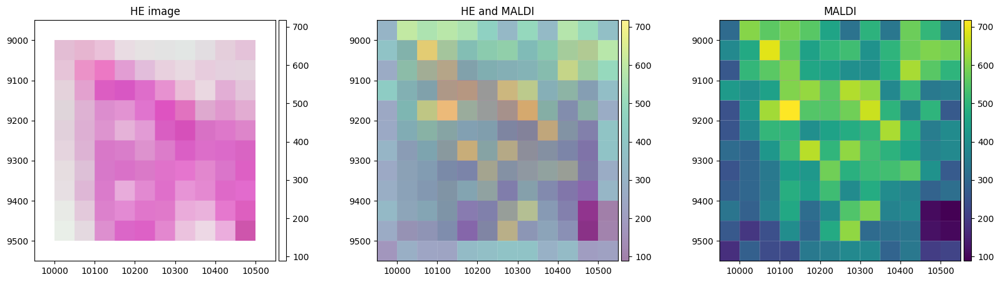

In [9]:
from spatialdata import bounding_box_query

xmin, xmax, ymin, ymax = 10000, 10500, 9000, 9500   # adjust to a region with clear features

crop = bounding_box_query(
    sdata, axes=("x", "y"),
    min_coordinate=[xmin, ymin], max_coordinate=[xmax, ymax],
    target_coordinate_system="global",
)

fig, axs = plt.subplots(1, 3, figsize=(20, 5), dpi=200)
crop.pl.render_images("he_image").pl.render_shapes("pixels", size=3, fill_alpha=0, color="MPI").pl.show("global", ax=axs[0], title="HE image")
crop.pl.render_images("he_image").pl.render_shapes("pixels", size=3, fill_alpha=0.5, color="MPI").pl.show("global", ax=axs[1], title="HE and MALDI")
crop.pl.render_images("he_image").pl.render_shapes("pixels", size=3, fill_alpha=1, color="MPI").pl.show("global", ax=axs[2], title="MALDI")
plt.show()

The following example demonstrates the segmentation artefacts that can occur when applying StarDist to an H&E image that does not have sufficient resolution:

<details><summary></summary>

In [10]:
sopa.make_image_patches(sdata,patch_width=1024,patch_overlap=64,image_key="he_image")

sopa.segmentation.stardist(
    sdata,
    model_type="2D_versatile_he",
    image_key="he_image",
    prob_thresh=0.6,
    nms_thresh=0.3,
    clip_limit=0.01,
    clahe_kernel_size=64,
    gaussian_sigma=0.5,
    key_added="cell_segmentation",
)

[INFO] (sopa.patches.patches) Added 810 patch(es) to sdata['image_patches']
[WARNING] (sopa._settings) Running without parallelization backend can be slow. Consider using a backend, e.g. via `sopa.settings.parallelization_backend = 'dask'`, or `export SOPA_PARALLELIZATION_BACKEND=dask`.
  0%|          | 0/810 [00:00<?, ?it/s]2026-11-03 15:33:27.467322: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-11-03 15:33:27.467385: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-11-03 15:33:27.467393: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1793684007.467586 1910907 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793684007.467801 1910907 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical P

[WARNING] (sopa.shapes._vectorize) No cell was returned by the segmentation
  1%|          | 5/810 [00:05<13:07,  1.02it/s]

[WARNING] (sopa.shapes._vectorize) No cell was returned by the segmentation
100%|██████████| 810/810 [20:28<00:00,  1.52s/it]
[INFO] (sopa.segmentation.stainings) Found 20767 total cells
Resolving conflicts: 100%|██████████| 11754/11754 [00:01<00:00, 9797.46it/s]
[INFO] (sopa.segmentation.stainings) Added 18997 cell boundaries in sdata['cell_segmentation']


functools.py (889): The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.


INFO     Value for parameter 'color' appears to be a color, using it as such.                                      


anndata.py (1758): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


INFO     Value for parameter 'color' appears to be a color, using it as such.                                      


anndata.py (1758): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
anndata.py (1758): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
_elements.py (108): Key `pixels` already exists. Overwriting it in-memory.
_elements.py (128): Key `maldi_adata` already exists. Overwriting it in-memory.
anndata.py (1758): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


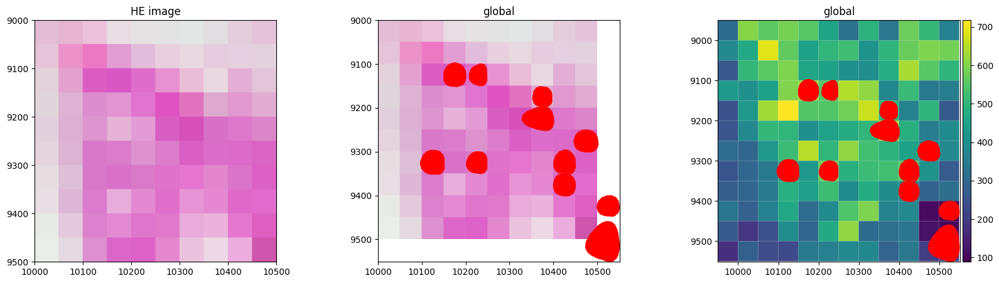

In [13]:
from spatialdata import bounding_box_query

xmin, xmax, ymin, ymax = 10000, 10500, 9000, 9500   # adjust to a region with clear features

crop = bounding_box_query(
    sdata, axes=("x", "y"),
    min_coordinate=[xmin, ymin], max_coordinate=[xmax, ymax],
    target_coordinate_system="global",
)

fig, axs = plt.subplots(1, 3, figsize=(20, 5), dpi=200)
crop.pl.render_images("he_image").pl.show("global", ax=axs[0], title="HE image")
crop.pl.render_images("he_image").pl.render_shapes("cell_segmentation", color="red").pl.show("global", ax=axs[1])
crop.pl.render_shapes("pixels", color = "MPI").pl.render_shapes("cell_segmentation", color="red").pl.show("global", ax=axs[2])
plt.show()

you can see the cell segmentation has failed and instead is simply mapping a pixel. 

</details>

This is only under the assumption that the auto alignment function has altered the HE image to a level which is not suitable for cell segmentation. If this is the case the steps below demostrate how to run cell segmentation on the full size image and then add that image back to the aligned `SpatialData` object.

### Running Cell Segmentation on Raw H&E Image

For this we will load in the H&E image directly to a `SpatialData` object using `gp.he_spatialdata`.

In [2]:
he = gp.he_spatialdata("/Users/andrewcauser/Documents/he_2x_viewer.ome.tif")

/Users/andrewcauser/goatpy/goatpy/io.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


Successfully loaded with sopa.io.wsi


After loading the H&E image into an *goatpy* we can then generate a tissue mask and run cell segmentation for all pixels within that tissue mask. To improve the speed we can use the `gp.add_pyramid` function to generate pyramidal downsampling sizes of our high resultion image if the supplied H&E only contains the full resolution image:

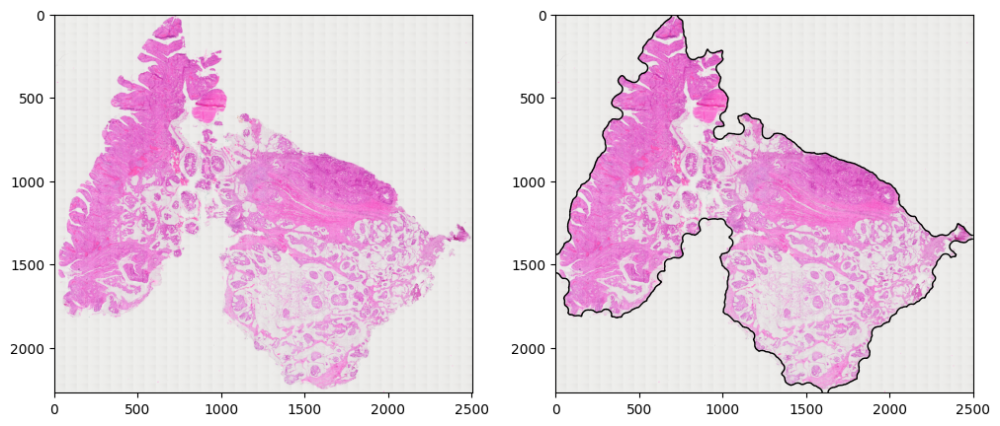

In [5]:
gp.add_pyramid(he) 
mask = gp.tissue_mask(he, thr_mult=0.3, close_size=61)

We can see our tissue has been segmented well. Now we can run `sopa.make_image_patches` to tile our image and `sopa.segmentation.stardist` to run cell nuclei segmentation on the H&E image:

In [ ]:
sopa.make_image_patches(he, patch_width=1024, patch_overlap=64, image_key="he_image_pyr")

sopa.segmentation.stardist(
    he,
    model_type="2D_versatile_he",
    image_key="he_image_pyr",
    prob_thresh=0.6,
    nms_thresh=0.3,
    clip_limit=0.01,
    clahe_kernel_size=64,
    gaussian_sigma=0.5,
    key_added="cell_segmentation",
)

[INFO] (sopa.patches.patches) Added 809 patch(es) to sdata['image_patches']
[WARNING] (sopa._settings) Running without parallelization backend can be slow. Consider using a backend, e.g. via `sopa.settings.parallelization_backend = 'dask'`, or `export SOPA_PARALLELIZATION_BACKEND=dask`.
  0%|          | 0/809 [00:00<?, ?it/s]2026-11-03 13:18:35.138973: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-11-03 13:18:35.139047: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-11-03 13:18:35.139055: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1793675915.139232 1736432 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793675915.139640 1736432 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical P

  1%|          | 5/809 [00:07<19:09,  1.43s/it]

100%|██████████| 809/809 [25:14<00:00,  1.87s/it]
[INFO] (sopa.segmentation.stainings) Found 185478 total cells
Resolving conflicts: 100%|██████████| 64834/64834 [00:24<00:00, 2664.62it/s]
[INFO] (sopa.segmentation.stainings) Added 166953 cell boundaries in sdata['cell_segmentation']


In [10]:
he

SpatialData object, with associated Zarr store: /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/he.zarr
├── Images
│     ├── 'he_image': DataArray[cyx] (3, 36341, 40044)
│     └── 'he_image_pyr': DataTree[cyx] (3, 36341, 40044), (3, 9085, 10011), (3, 2271, 2502), (3, 567, 625)
└── Shapes
      ├── 'cell_segmentation': GeoDataFrame shape: (166953, 1) (2D shapes)
      ├── 'image_patches': GeoDataFrame shape: (809, 3) (2D shapes)
      └── 'region_of_interest': GeoDataFrame shape: (1, 1) (2D shapes)
with coordinate systems:
    ▸ 'global', with elements:
        he_image (Images), he_image_pyr (Images), cell_segmentation (Shapes), image_patches (Shapes), region_of_interest (Shapes)

we can see that the segmentation has been added to the `Shapes` layer called `cell_segmentaiton`. Below we will visualuse the results: 

INFO     Value for parameter 'color' appears to be a color, using it as such.                                      
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


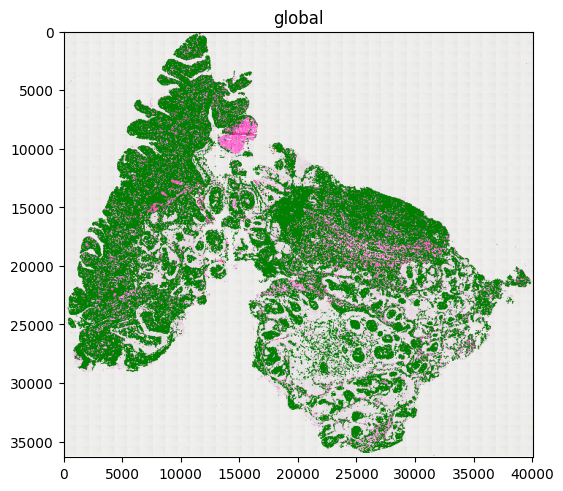

In [ ]:
he.pl.render_images("he_image").pl.render_shapes("cell_segmentation", color="green", alpha=1).pl.show()

INFO     Value for parameter 'color' appears to be a color, using it as such.                                      


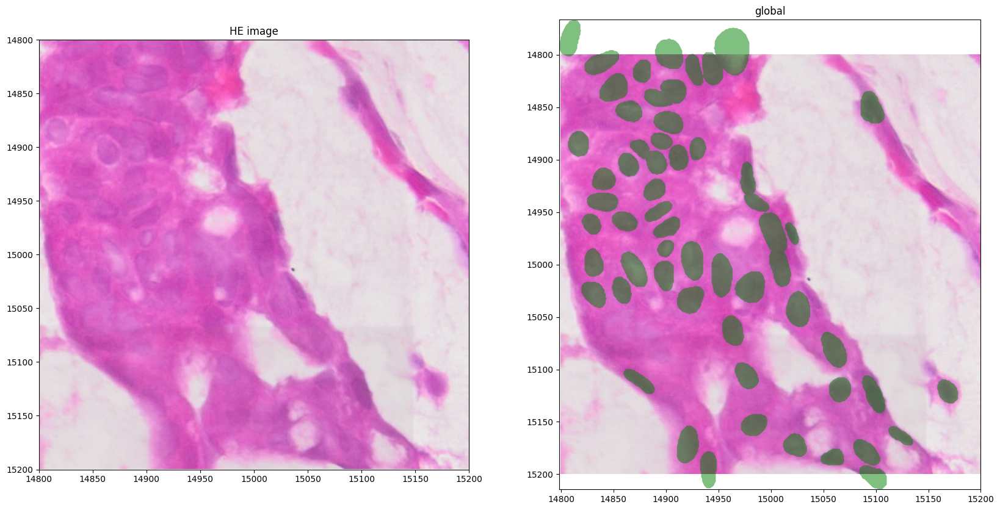

In [28]:
from spatialdata import bounding_box_query
import matplotlib.pyplot as plt
import spatialdata_plot

xmin, xmax, ymin, ymax = 14800, 15200, 14800, 15200   # adjust to a region with clear features

crop = bounding_box_query(
    he, axes=("x", "y"),
    min_coordinate=[xmin, ymin], max_coordinate=[xmax, ymax],
    target_coordinate_system="global",
)

fig, axs = plt.subplots(1,2, figsize=(20, 10), dpi=200)
crop.pl.render_images("he_image").pl.show("global", ax=axs[0], title="HE image")
crop.pl.render_images("he_image").pl.render_shapes("cell_segmentation", color="green", fill_alpha = 0.5).pl.show("global", ax=axs[1])
plt.show()

The next step is to add these cell segmentation results and the full resolution H&E image back to the original sdata object. 

In [19]:
he = read_zarr("/Users/andrewcauser/Documents/Grifith/test_data/IHC_new/he.zarr")
sdata = read_zarr("/Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To

In [20]:
gp.add_fullres_to_sdata(sdata, he, 
                     image_key="he_image_pyr",
                     shapes_keys=("cell_segmentation", "region_of_interest"),
                     image_key_out="he_fullres",
)

version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)


SpatialData object, with associated Zarr store: /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata.zarr
├── Images
│     ├── 'he_fullres': DataTree[cyx] (3, 36341, 40044), (3, 9085, 10011), (3, 2271, 2502), (3, 567, 625)
│     └── 'he_image': DataArray[cyx] (3, 25800, 28350)
├── Points
│     └── 'centroids': DataFrame with shape: (<Delayed>, 3) (2D points)
├── Shapes
│     ├── 'cell_segmentation': GeoDataFrame shape: (166953, 1) (2D shapes)
│     ├── 'pixels': GeoDataFrame shape: (267648, 2) (2D shapes)
│     └── 'region_of_interest': GeoDataFrame shape: (1, 1) (2D shapes)
└── Tables
      └── 'maldi_adata': AnnData (267648, 174)
with coordinate systems:
    ▸ 'global', with elements:
        he_fullres (Images), he_image (Images), centroids (Points), cell_segmentation (Shapes), pixels (Shapes), region_of_interest (Shapes)
with the following Dask-backed elements not being self-contained:
    ▸ he_fullres: /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/he.zarr/images

The `sdata` *goatpy* object now has the cell_segmentation and high resolution image aligned. Below we will plot the cell segmentation results on the originally aligned `he_image` compared to the now aligned high resolution `he_fullres`:

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/functools.py:889: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


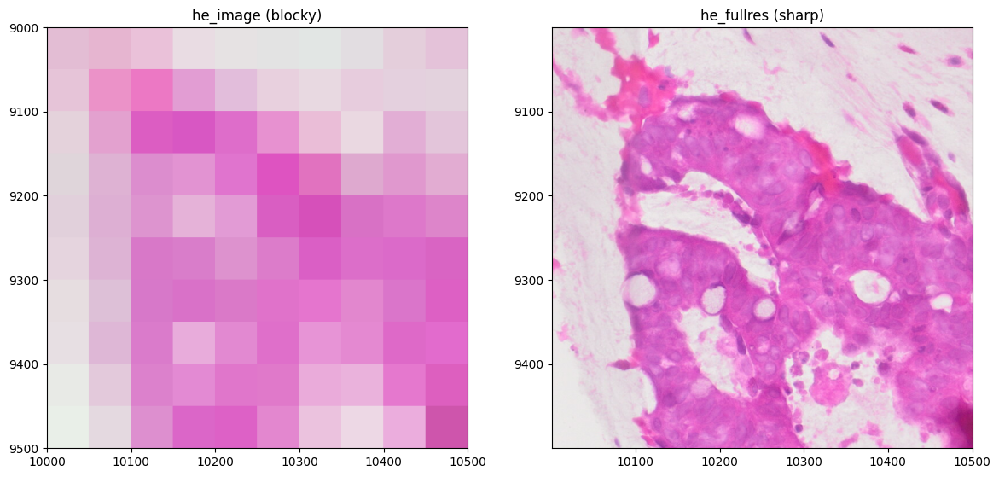

In [21]:
from spatialdata import bounding_box_query

xmin, xmax, ymin, ymax = 10000, 10500, 9000, 9500   # adjust to a region with clear features

crop = bounding_box_query(
    sdata, axes=("x", "y"),
    min_coordinate=[xmin, ymin], max_coordinate=[xmax, ymax],
    target_coordinate_system="global",
)

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
crop.pl.render_images("he_image").pl.show("global", ax=axs[0], title="he_image (blocky)")
crop.pl.render_images("he_fullres").pl.show("global", ax=axs[1], title="he_fullres (sharp)")
plt.show()

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-pac

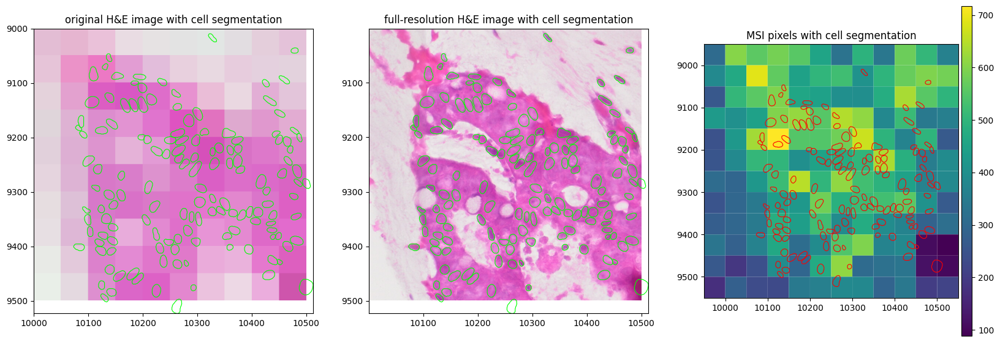

In [37]:
fig, axs = plt.subplots(1, 3, figsize=(20, 7))

crop.pl.render_images("he_image").pl.render_shapes(
    "cell_segmentation", fill_alpha=0, outline_alpha=1, outline_color="lime", outline_width=0.8
).pl.show("global", ax=axs[0], title="original H&E image with cell segmentation")

crop.pl.render_images("he_fullres").pl.render_shapes(
    "cell_segmentation", fill_alpha=0, outline_alpha=1, outline_color="lime", outline_width=0.8
).pl.show("global", ax=axs[1], title="full-resolution H&E image with cell segmentation")

crop.pl.render_shapes("pixels", color = "MPI").pl.render_shapes(
    "cell_segmentation", fill_alpha=0, outline_alpha=1, outline_color="red", outline_width=0.8
).pl.show("global", ax=axs[2], title="MSI pixels with cell segmentation")

plt.show()


### Visualising Cell Segmentation Results

One fanstastic way to visualise the cell segmentation results with *goatpy* is through using the specialised `Napari` based GUI:

In [35]:
gp.launch_goatpy_gui(sdata)

2026-11-03 17:17:02.585 | WARNING  | napari_spatialdata._viewer:__init__:57 - Due to Shift-L being used as shortcut in napari, it is being deprecated and might not link a new layer to an existing SpatialData object in the viewer. Please use ⌘-L on MacOS or else Ctrl-L.
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


[goatpy GUI] Added 'he_image' (images) in 'global'


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


[goatpy GUI] Added 'he_fullres' (images) in 'global'


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


[goatpy GUI] Added 'pixels' (shapes) in 'global'


... (9 outputs left out)

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO: Please wait for the current operation to finish.


2026-11-03 17:18:07.068 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-11-03 17:18:08.895 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
2026-11-03 17:18:10.810 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
2026-11-03 17:18:53.980 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-11-03 17:18:54.765 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.


INFO: Selected 166953 shapes in this slice.


<div align="center">
    <img src="../../_static/tutorial_images/single_cell_highres.png" width="800">
</div>


### Additional Analysis

After running cell segmentation there are various intereseting analyses that can be performed. 

Below we will demonstrate some key methods with interesting finding:

#### Identifying number of cells per pixel

The number of cells per pixel can often tell us many things about particular regions of the tissue. One interesting finding would be to see if any glycans correlate to the number of cells present per pixel.

To calculate this first we will use the `gp.add_n_cells_per_pixel` to add a column in the `sdata["maldi_adata"].obs` dataframe stating the number of cells per pixel.

In [ ]:
sdata = gp.add_n_cells_per_pixel( sdata,
    table_key="maldi_adata",
    cells_key = "cell_segmentation",
    pixels_key = "pixels",
    coordinate_system = "global")

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     


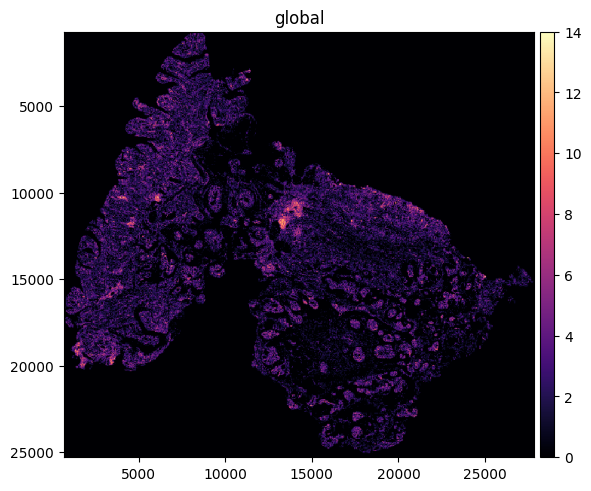

In [43]:
sdata.pl.render_shapes("pixels", color = "n_cells", cmap = "magma").pl.show()

Assessing the plot above we can see there are definetly particular regions of the tissue that have more cells per pixel than others. To identify common glycans which correlate with this, use the `gp.spatial_autocorrelation` function:

In [47]:
df = gp.spatial_autocorrelation(sdata, gt = "n_cells", table_key="maldi_adata", 
                           pixels_key="pixels", coordinate_system="global")

df.head()

,mz,bivariate_moran_I,pearson_r
0,1581.68,0.556381,0.571711
1,1435.6,0.554767,0.566893
2,1921.76,0.553771,0.568301
3,1403.63,0.551737,0.565086
4,1597.65,0.550027,0.560172


Based on the results from our auto-correlation analysis the m/z values of `1581.68` and `1435.6` correlate the most to the number of cells. To confirm this we can plot these glycan spatially against the number of cells:

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                
INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                
INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                
INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     


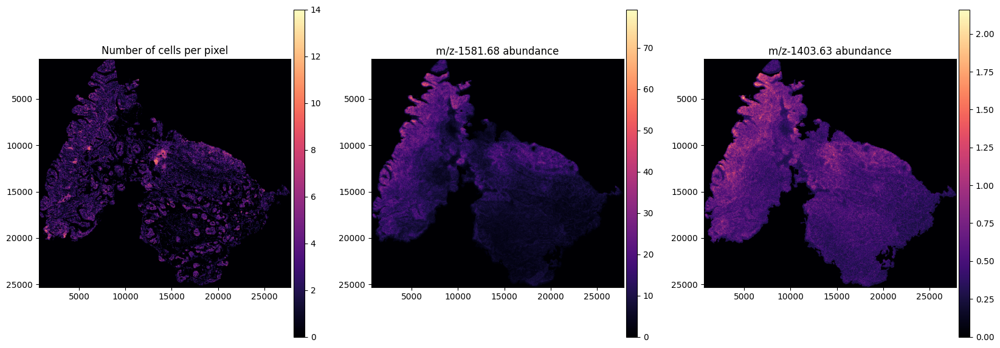

In [61]:
fig, axs = plt.subplots(1, 3, figsize=(20, 7))

sdata.pl.render_shapes("pixels", color = "n_cells", cmap = "magma"
                       ).pl.show("global", ax=axs[0], title="Number of cells per pixel")

sdata.pl.render_shapes("pixels", color = df["mz"][0], cmap = "magma"
                       ).pl.show("global", ax=axs[1], title= "m/z-" + str(df["mz"][0]) + " abundance")

sdata.pl.render_shapes("pixels", color = df["mz"][3], cmap = "magma"
                       ).pl.show("global", ax=axs[2], title="m/z-" + str(df["mz"][3]) + " abundance")

plt.show()

We can see that there are some m/z values that are positively correlated with the number of cells per pixel, in particular these m/z values seem to correlate well to malignant regions. Cancer cells are known to be highly proliferative, supporting the theory these metabolites may correlate to malignancy.

In addition to simply looking at data at a pixel level, we can use *goatpy* to transfer our pixel level data to a single cell level. This can be achived using `gp.pixel_to_cells`. This function creates a new `Anndata` object corresponding to each cell and is stored in the `Tables` section of the same `SpatialData` object. There are also parameters, such as min_coverage, that determine the minimum proportion of a cell that must overlap with a MALDI pixel for the cell to be assigned the corresponding pixel data.

In [5]:
gp.pixels_to_cells(
    sdata,
    pixel_layer="pixels",
    cell_layer="cell_segmentation",
    table_name="maldi_adata",
    coordinate_system="global",
    key_added = "cell_adata",
    overwrite = True,         
    min_coverage=0.5,           # require at least half the cell to be on MALDI data
)

Dropping 11/166953 cells with insufficient MALDI coverage.


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/models/models.py:1144: UserWarning: Converting `region_key: region` to categorical dtype.
  return convert_region_column_to_categorical(adata)


AnnData object with n_obs × n_vars = 166942 × 174
    obs: 'n_pixels', 'frac_cell_covered', 'max_pixel_weight', 'cell_area', 'cell_id', 'region'
    uns: 'pixel_ids', 'spatial_coordinate_system', 'pixels_to_cells', 'spatialdata_attrs'
    obsm: 'pixel_weights', 'spatial'

In [6]:
sdata

SpatialData object, with associated Zarr store: /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_cell_segmentations.zarr
├── Images
│     ├── 'he_fullres': DataTree[cyx] (3, 36341, 40044), (3, 9085, 10011), (3, 2271, 2502), (3, 567, 625)
│     └── 'he_image': DataArray[cyx] (3, 25800, 28350)
├── Points
│     └── 'centroids': DataFrame with shape: (<Delayed>, 3) (2D points)
├── Shapes
│     ├── 'cell_segmentation': GeoDataFrame shape: (166953, 1) (2D shapes)
│     ├── 'pixels': GeoDataFrame shape: (267648, 2) (2D shapes)
│     └── 'region_of_interest': GeoDataFrame shape: (1, 1) (2D shapes)
└── Tables
      ├── 'cell_adata': AnnData (166942, 174)
      └── 'maldi_adata': AnnData (267648, 174)
with coordinate systems:
    ▸ 'global', with elements:
        he_fullres (Images), he_image (Images), centroids (Points), cell_segmentation (Shapes), pixels (Shapes), region_of_interest (Shapes)

After running the function above we have a new `Tables` variable called `cell_adata` which contains the `AnnData` data relative to each cell.

In [7]:
sdata["cell_adata"]

AnnData object with n_obs × n_vars = 166942 × 174
    obs: 'n_pixels', 'frac_cell_covered', 'max_pixel_weight', 'cell_area', 'cell_id', 'region'
    uns: 'pixel_ids', 'spatial_coordinate_system', 'pixels_to_cells', 'spatialdata_attrs'
    obsm: 'pixel_weights', 'spatial'

Now that we have a seperate `Tables` entry for our single-cell data, we can also run clustering on these cells and get clustering results at a psuedo-single cell level:

In [ ]:
sdata = read_zarr("/Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_cell_segmentations.zarr")
%matplotlib inline

version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [43]:
sdata.write("/Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_clustering.zarr")

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_clustering.zarr). Please  
         see the documentation of `is_self_contained()` to understand the implications of working with SpatialData 
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from                                                              
         /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_cell_segmentations.zarr the new file path:  
         /Users/andrewcauser/Documents/Grifith/test_data/IHC_new/sdata_clustering.zarr                             


In [3]:
## Pixel Level Clustering
sdata = gp.graphpca_spatialdata(sdata, tables= "maldi_adata",library_id= 'spatial',n_components = 30, n_neighbors = 15, alpha = 0.5)
sdata = gp.get_kmean_clusters(sdata, tables= "maldi_adata",n_clusters = 12) 

In [40]:
## Cell Level Clustering
sdata = gp.graphpca_spatialdata(sdata, tables= "cell_adata",library_id= 'spatial',n_components = 30, n_neighbors = 15, alpha = 0.5)
sdata = gp.get_kmean_clusters(sdata, tables= "cell_adata",n_clusters = 12) 

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-pac

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata_plot/pl/utils.py:800: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_82355/1085061000.py:8: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(sdata.tables["cell_adata"], img_key="hires",


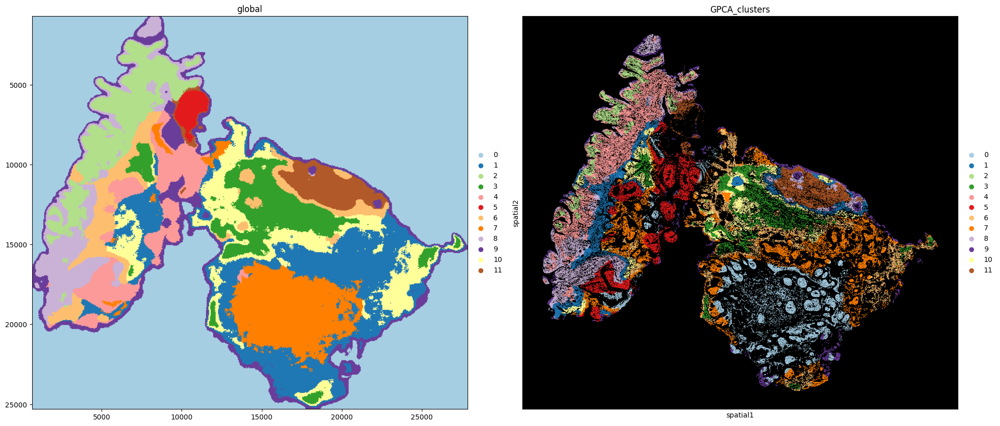

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(20, 10), dpi=200)

axes[1].set_facecolor("black")

sdata.pl.render_shapes("pixels", color="GPCA_clusters",cmap = "Paired", 
                       table_name="maldi_adata").pl.show(ax=axes[0], coordinate_systems="global")

sc.pl.spatial(sdata.tables["cell_adata"], img_key="hires",
              color=["GPCA_clusters"], size=4, spot_size=10,
              alpha_img=0,ax= axes[1], show=False)


plt.tight_layout()
fig.savefig("/Users/andrewcauser/Documents/Grifith/test_data/figures/clustering.png", dpi=300)
plt.show()

We can see the single cell clustering identfies may key areas similar to the pixel level clustering, but with more detail. The single cell clustering also identifies some areas that are not identified in the pixel level clustering, such as regions of cluster 1. This simall region of cells was not seperated using pixel level clustering. Lets zoom in an have a closer look. 

INFO     Rasterizing image for faster rendering.                                                                   


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-pac

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata_plot/pl/utils.py:800: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_82355/2114635334.py:54: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(sdata.tables["cell_adata"], img_key="hires",
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/functools.py:889: UserWarning: The object has `points` element. Depending on the number of points, querying M

INFO     Rasterizing image for faster rendering.                                                                   


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/sit

... (4 outputs left out)

INFO     Rasterizing image for faster rendering.                                                                   


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/sit

INFO     Rasterizing image for faster rendering.                                                                   


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/sit

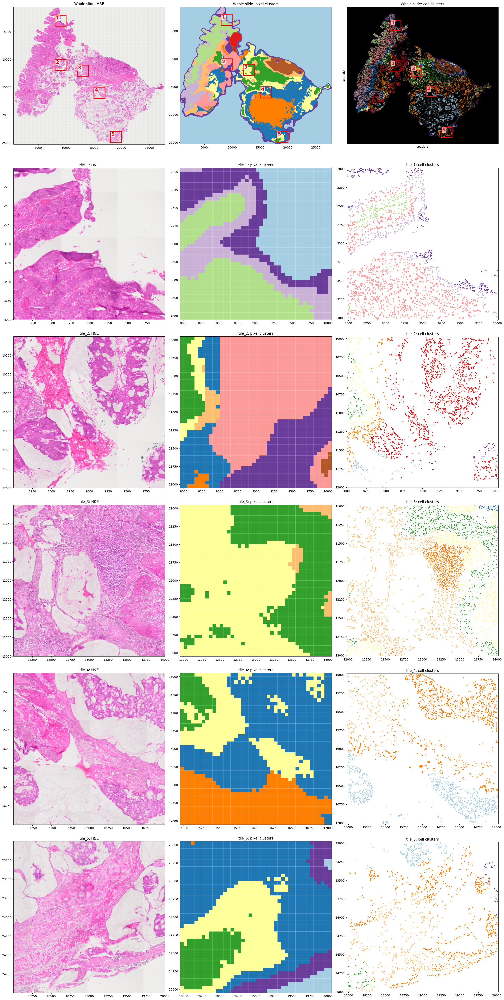

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import spatialdata_plot
from spatialdata import bounding_box_query

tile = 2000
tiles = {
    "tile_1": (8000, 2000),
    "tile_2": (8000, 10000),
    "tile_3": (12000, 11000),
    "tile_4": (15000, 15000),
    "tile_5": (18000, 23000),
}
boxes = {k: (v[0], v[1], v[0] + tile, v[1] + tile) if len(v) == 2 else tuple(v)
         for k, v in tiles.items()}

cs = "global"
pixel_table, pixel_key = "maldi_adata", "GPCA_clusters"
cell_table,  cell_key  = "cell_adata",  "GPCA_clusters"

def set_palette(adata, key, cmap="Paired"):
    adata.obs[key] = adata.obs[key].astype("category")
    cm = plt.get_cmap(cmap)
    n = len(adata.obs[key].cat.categories)
    adata.uns[f"{key}_colors"] = [matplotlib.colors.to_hex(cm(i % cm.N)) for i in range(n)]

set_palette(sdata[pixel_table], pixel_key)
set_palette(sdata[cell_table],  cell_key)

def draw_boxes(ax):
    """Outline each tile and label it, in global data coordinates."""
    for name, (x0, y0, x1, y1) in boxes.items():
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0,
                               fill=False, edgecolor="red", linewidth=2.5))
        ax.text(x0 + 150, y0 + 150, name.replace("tile_", ""), color="red",
                fontsize=16, fontweight="bold", va="top",
                bbox=dict(facecolor="white", alpha=0.7, pad=2, edgecolor="none"))

n = len(boxes)
fig, axs = plt.subplots(n + 1, 3, figsize=(24, 8 * (n + 1)))

axs[0, 2].set_facecolor("black")

# ---- row 0: whole slide ----
sdata.pl.render_images("he_fullres").pl.show(
    cs, ax=axs[0, 0], title="Whole slide: H&E", colorbar=False)

sdata.pl.render_shapes(
    "pixels", color=pixel_key, cmap="Paired", table_name=pixel_table,
).pl.show(cs, ax=axs[0, 1], title="Whole slide: pixel clusters", legend_loc=None)

sc.pl.spatial(sdata.tables["cell_adata"], img_key="hires",
              color=["GPCA_clusters"], size=3, spot_size=10,
              alpha_img=0,ax=axs[0, 2], title="Whole slide: cell clusters", legend_loc=None,show=False)


for ax in axs[0]:
    draw_boxes(ax)

# ---- rows 1..n: tiles ----
for r, (name, (x0, y0, x1, y1)) in enumerate(boxes.items(), start=1):
    crop = bounding_box_query(
        sdata, axes=("x", "y"),
        min_coordinate=[x0, y0], max_coordinate=[x1, y1],
        target_coordinate_system=cs,
    )
    crop.pl.render_images("he_fullres").pl.show(
        cs, ax=axs[r, 0], title=f"{name}: H&E", colorbar=False)

    crop.pl.render_shapes(
        "pixels", color=pixel_key, cmap="Paired", fill_alpha=1, outline_alpha=0,
        table_name=pixel_table,
    ).pl.show(cs, ax=axs[r, 1], title=f"{name}: pixel clusters", legend_loc=None)

    crop.pl.render_shapes(
        "cell_segmentation", color=cell_key, cmap="Paired", fill_alpha=1, outline_alpha=0,
        table_name=cell_table,
    ).pl.show(cs, ax=axs[r, 2], title=f"{name}: cell clusters", legend_loc=None)

plt.tight_layout()
plt.show()


From these zoom in we can see that the cell segmentation has worked well and clustering based on cells reveals biology that pixel clustering does not. ROI 3 shows a clear group of cells (orange) which match the H&E but are not present in the pixel level clustering results. 

24490 of 24490 cluster-7 cells matched to shapes


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `cells_cluster7` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Rasterizing image for faster rendering.                                                                   


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `cluster7_region` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/functools.py:889: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     Value for parameter 'color' appears to be a color, using it as such.                                      
INFO     Rasterizing image for faster rendering.                                                                   


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     Value for parameter 'color' appears to be a color, using it as such.                                      
INFO     Value for parameter 'color' appears to be a color, using it as such.                                      
INFO     Rasterizing image for faster rendering.                                                                   


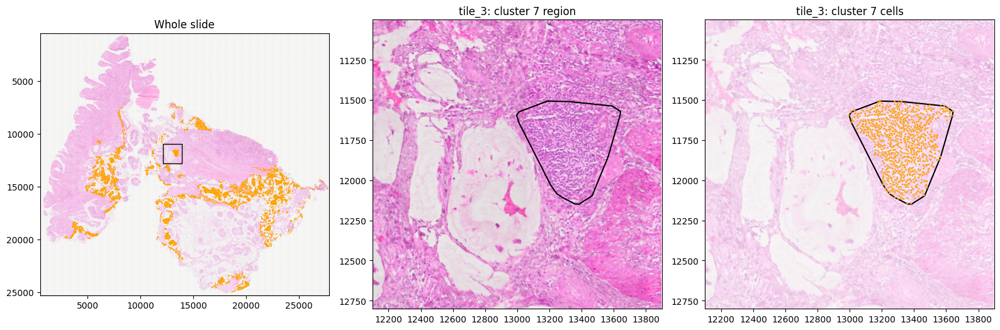

In [ ]:
import geopandas as gpd
import shapely
import spatialdata as sd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from spatialdata import bounding_box_query
from shapely.geometry import box
from spatialdata.models import ShapesModel
from spatialdata.transformations import get_transformation, Identity


adata = sdata["cell_adata"]
inst_key = adata.uns["spatialdata_attrs"]["instance_key"]
ids = adata.obs.loc[adata.obs["GPCA_clusters"].astype(str) == "7", inst_key]

shp = sdata["cell_segmentation"]
mask = shp.index.isin(ids)
print(f"{mask.sum()} of {len(ids)} cluster-7 cells matched to shapes")   # should be equal

sub = gpd.GeoDataFrame(geometry=shp.geometry[mask].values, index=shp.index[mask])
sdata["cells_cluster7"] = ShapesModel.parse(
    sub, transformations=get_transformation(shp, get_all=True)
)


tile = 1800
x0, y0 = 12100, 11000            # tile_3 corner (global coords)
x1, y1 = x0 + tile, y0 + tile

# centroids of cluster 7 in global coords
g = sd.transform(sdata["cells_cluster7"], to_coordinate_system="global")
cen = g.geometry.centroid
in_tile = cen.within(box(x0, y0, x1, y1))
pts = shapely.MultiPoint(list(zip(cen[in_tile].x, cen[in_tile].y)))

region = pts.convex_hull

region_gdf = gpd.GeoDataFrame(geometry=[region])
sdata["cluster7_region"] = ShapesModel.parse(
    region_gdf, transformations={"global": Identity()}
)


fig, axs = plt.subplots(1, 3, figsize=(16, 8))

# ---- left: whole slide with the tile outlined ----
ax = axs[0]
sdata.pl.render_images("he_fullres", alpha=0.5).pl.show("global", ax=ax, title="Whole slide")
xlim, ylim = ax.get_xlim(), ax.get_ylim()
ax.scatter(cen.x, cen.y, s=0.3, c="orange", linewidths=0)
ax.add_patch(Rectangle((x0, y0), tile, tile, fill=False, edgecolor="black", linewidth=1))
ax.set_xlim(xlim); ax.set_ylim(ylim)

# ---- right: crop, cluster 7 only ----
crop = bounding_box_query(
    sdata, axes=("x", "y"),
    min_coordinate=[x0, y0], max_coordinate=[x1, y1],
    target_coordinate_system="global",
)
crop.pl.render_images("he_fullres", alpha=1).pl.render_shapes(
    "cluster7_region", fill_alpha=0, color="orange",
    outline_alpha=1, outline_color="black", outline_width=1.5,
).pl.show("global", ax=axs[1], title="tile_3: cluster 7 region")

crop.pl.render_images("he_fullres", alpha=0.4).pl.render_shapes(
    "cluster7_region", fill_alpha=0, color="orange",
    outline_alpha=1, outline_color="black", outline_width=1.5,
).pl.render_shapes(
    "cells_cluster7", color="orange", fill_alpha=1,
).pl.show("global", ax=axs[2], title="tile_3: cluster 7 cells")

plt.tight_layout()
plt.show()

Based on these results, we can see that this group of cells identified as cluster 7 map closely with immune cells surrounding the tumour region. 
The next step is to identify the m/z features that are associated with this cluster of cells.

In [56]:
df = gp.spatial_autocorrelation(sdata, gt=("GPCA_clusters", "7"), table_key="cell_adata", pixels_key="cell_segmentation",coordinate_system="global")
df.head(8)

,mz,bivariate_moran_I,pearson_r
0,1743.73,-0.305836,-0.308403
1,933.47,-0.301180,-0.302876
2,1079.53,-0.297922,-0.299567
3,1905.78,-0.289132,-0.291684
4,1419.63,-0.287373,-0.290268
5,1095.52,-0.285108,-0.287120
6,1581.68,-0.284837,-0.288209
7,1850.82,0.267678,0.262308


/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_82355/4032061226.py:10: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_82355/4032061226.py:15: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, img_key="hires", color="1743.73", size=5, spot_size=10,
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_82355/4032061226.py:17: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, img_key="hires", color="1850.82", size=5, spot_size=10,


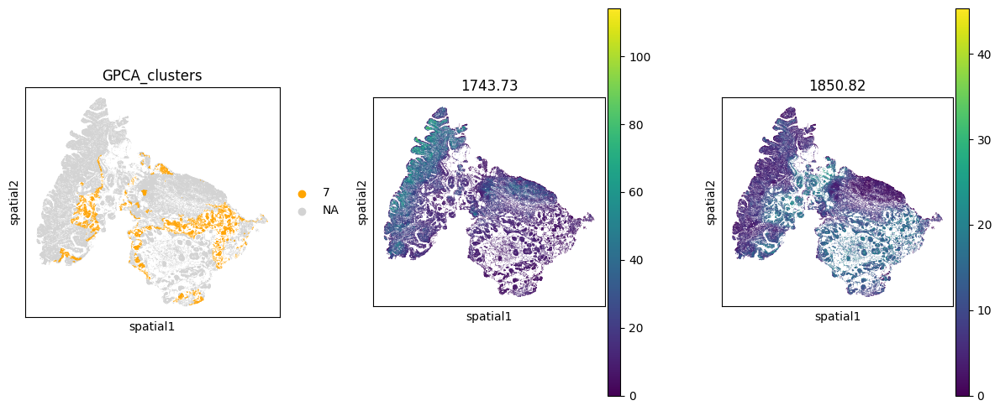

In [58]:
adata = sdata.tables["cell_adata"]
adata.obs["GPCA_clusters"] = adata.obs["GPCA_clusters"].astype(str).astype("category")

# every category gets an entry; only cluster 7 is orange
palette = {c: "lightgrey" for c in adata.obs["GPCA_clusters"].cat.categories}
palette["7"] = "orange"

fig, ax = plt.subplots(1, 3, figsize=(12, 5))

sc.pl.spatial(
    adata, img_key="hires", groups=["7"], color="GPCA_clusters",
    palette=palette, na_color="lightgrey",
    size=5, spot_size=10, alpha_img=1, ax=ax[0], show=False,
)
sc.pl.spatial(adata, img_key="hires", color="1743.73", size=5, spot_size=10,
              cmap="viridis", ax=ax[1], show=False)
sc.pl.spatial(adata, img_key="hires", color="1850.82", size=5, spot_size=10,
              alpha_img=1, ax=ax[2], show=False)

plt.tight_layout()
plt.show()

By plotting these two m/z values, we can observe a negative correlation between `m/z-1743.73` and cluster 7, and a positive correlation between `m/z-1850.82` and cluster 7. These results may suggest that the abundance of `m/z-1743.73` is associated with malignant cells, whereas `m/z-1850.82` is associated with immune infiltration.

### Using Manual Aligment Data

For running cell segmentation on mannually aligned data there is a slightly different approach needed as the aligned data is stored in the `aligned` coordinate_system. Below demonstrates an example of how to run cell segmentation on a sample aligned using *goatpy's* 'manual alignment' method:


In [130]:
import goatpy as gp
from spatialdata import read_zarr
import spatialdata_plot
import matplotlib.pyplot as plt
import scanpy as sc
import sopa

sdata = read_zarr("/Users/andrewcauser/Documents/Griffith/test_data/ovarian_aligned_finalised.zarr")


version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwar

In [ ]:
sdata

SpatialData object, with associated Zarr store: /Users/andrewcauser/Documents/Griffith/test_data/ovarian_aligned_finalised.zarr
├── Images
│     ├── 'he_image': DataArray[cyx] (3, 19160, 23633)
│     └── 'optical_image': DataTree[cyx] (3, 12400, 6000), (3, 6200, 3000), (3, 3100, 1500), (3, 1550, 750)
├── Points
│     ├── 'centroids': DataFrame with shape: (<Delayed>, 112) (2D points)
│     ├── 'he_landmarks': DataFrame with shape: (<Delayed>, 2) (2D points)
│     └── 'maldi_landmarks': DataFrame with shape: (<Delayed>, 2) (2D points)
├── Shapes
│     ├── 'Annotations': GeoDataFrame shape: (7, 5) (2D shapes)
│     └── 'pixels': GeoDataFrame shape: (16455, 2) (2D shapes)
└── Tables
      └── 'maldi_adata': AnnData (16455, 108)
with coordinate systems:
    ▸ 'aligned', with elements:
        he_image (Images), optical_image (Images), centroids (Points), he_landmarks (Points), maldi_landmarks (Points), Annotations (Shapes), pixels (Shapes)
    ▸ 'global', with elements:
        he_image (I

After loading the data and examining its structure, we can see that the dataset contains `aligned` coordinates stored in the aligned coordinate system. To use `SOPA's StarDist` implementation, we need to use helper functions such `as gp.make_gp_image_patches`. Here, we need to specify the `aligne`d` coordinate system.

In [ ]:
gp.make_gp_image_patches(sdata, image_key="he_image", coordinate_system="aligned", roi_key="pixels", patch_width=2000, patch_overlap=50)

[INFO] (sopa.patches.patches) Added 17 patch(es) to sdata['image_patches']


SpatialData object, with associated Zarr store: /Users/andrewcauser/Documents/Griffith/test_data/ovarian_aligned_finalised.zarr
├── Images
│     ├── 'he_image': DataArray[cyx] (3, 19160, 23633)
│     └── 'optical_image': DataTree[cyx] (3, 12400, 6000), (3, 6200, 3000), (3, 3100, 1500), (3, 1550, 750)
├── Points
│     ├── 'centroids': DataFrame with shape: (<Delayed>, 112) (2D points)
│     ├── 'he_landmarks': DataFrame with shape: (<Delayed>, 2) (2D points)
│     └── 'maldi_landmarks': DataFrame with shape: (<Delayed>, 2) (2D points)
├── Shapes
│     ├── 'Annotations': GeoDataFrame shape: (7, 5) (2D shapes)
│     ├── 'image_patches': GeoDataFrame shape: (17, 3) (2D shapes)
│     └── 'pixels': GeoDataFrame shape: (16455, 2) (2D shapes)
└── Tables
      └── 'maldi_adata': AnnData (16455, 108)
with coordinate systems:
    ▸ 'aligned', with elements:
        he_image (Images), optical_image (Images), centroids (Points), he_landmarks (Points), maldi_landmarks (Points), Annotations (Shapes),

Now, `sopa.segmentation.stardist` can be run on the data.

Note: When using the manual alignment method, the H&E resolution is often maintained, meaning it is safe to perform segmentation on the `aligned` H&E image. However, always check the resolution and quality of the data before running this step to determine the most appropriate approach.

In [ ]:
sopa.segmentation.stardist(
    sdata,
    model_type="2D_versatile_he",
    image_key="he_image",
    prob_thresh=0.1,
    nms_thresh=0.5,
    clip_limit=0.02,
    clahe_kernel_size=25,
    gaussian_sigma=1,
    key_added="cell_segmentation",
)

[WARNING] (sopa._settings) Running without parallelization backend can be slow. Consider using a backend, e.g. via `sopa.settings.parallelization_backend = 'dask'`, or `export SOPA_PARALLELIZATION_BACKEND=dask`.
  0%|          | 0/17 [00:00<?, ?it/s]2026-10-21 11:29:15.217907: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-10-21 11:29:15.218004: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-21 11:29:15.218020: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1792546155.218423 3253574 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792546155.219434 3253574 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-10-21 1

 29%|██▉       | 5/17 [00:41<01:28,  7.40s/it]

100%|██████████| 17/17 [02:06<00:00,  7.42s/it]
[INFO] (sopa.segmentation.stainings) Found 28081 total cells
Resolving conflicts: 100%|██████████| 29590/29590 [00:02<00:00, 12802.40it/s]
[INFO] (sopa.segmentation.stainings) Added 26914 cell boundaries in sdata['cell_segmentation']


In [ ]:
sdata

SpatialData object, with associated Zarr store: /Users/andrewcauser/Documents/Griffith/test_data/ovarian_aligned_finalised.zarr
├── Images
│     ├── 'he_image': DataArray[cyx] (3, 19160, 23633)
│     └── 'optical_image': DataTree[cyx] (3, 12400, 6000), (3, 6200, 3000), (3, 3100, 1500), (3, 1550, 750)
├── Points
│     ├── 'centroids': DataFrame with shape: (<Delayed>, 112) (2D points)
│     ├── 'he_landmarks': DataFrame with shape: (<Delayed>, 2) (2D points)
│     └── 'maldi_landmarks': DataFrame with shape: (<Delayed>, 2) (2D points)
├── Shapes
│     ├── 'Annotations': GeoDataFrame shape: (7, 5) (2D shapes)
│     ├── 'cell_segmentation': GeoDataFrame shape: (26914, 1) (2D shapes)
│     ├── 'image_patches': GeoDataFrame shape: (17, 3) (2D shapes)
│     └── 'pixels': GeoDataFrame shape: (16455, 2) (2D shapes)
└── Tables
      └── 'maldi_adata': AnnData (16455, 108)
with coordinate systems:
    ▸ 'aligned', with elements:
        he_image (Images), optical_image (Images), centroids (Point

The cell segmentation is now available in the `cell_segmentation` layer of the `sdata` object. Lets visualize it using the following code:

INFO     Value for parameter 'color' appears to be a color, using it as such.                                      
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


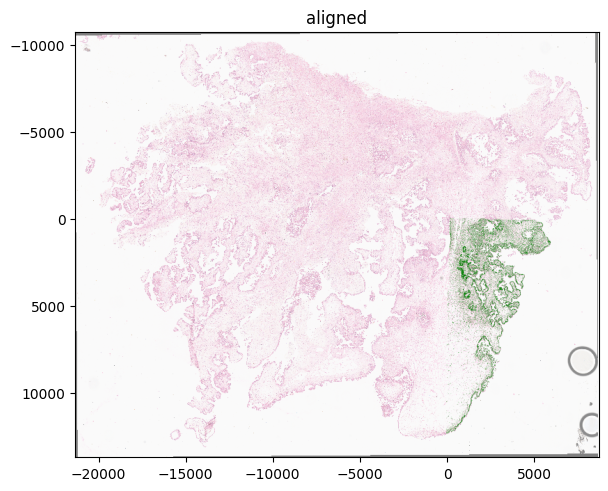

In [ ]:
sdata.pl.render_images("he_image", alpha=0.5).pl.render_shapes("cell_segmentation", color="green", alpha=1).pl.show("aligned")

In [ ]:
gp.launch_goatpy_gui(sdata)

2026-10-20 12:52:30.666 | WARNING  | napari_spatialdata._viewer:__init__:57 - Due to Shift-L being used as shortcut in napari, it is being deprecated and might not link a new layer to an existing SpatialData object in the viewer. Please use ⌘-L on MacOS or else Ctrl-L.


[goatpy GUI] Added 'he_image' (images) in 'aligned'


aligned_df.py (68): Transforming to str index.


INFO: Please wait for the current operation to finish.
[goatpy GUI] Added 'optical_image' (images) in 'aligned'
INFO: Please wait for the current operation to finish.
[goatpy GUI] Added 'Annotations' (shapes) in 'aligned'
INFO: Please wait for the current operation to finish.
[goatpy GUI] Added 'pixels' (shapes) in 'aligned'
INFO: Please wait for the current operation to finish.
[goatpy GUI] Added 'image_patches' (shapes) in 'aligned'
INFO: Please wait for the current operation to finish.
[goatpy GUI] Added 'cell_segmentation' (shapes) in 'aligned'
INFO: Please wait for the current operation to finish.
[goatpy GUI] Added 'centroids' (points) in 'aligned'
INFO: Please wait for the current operation to finish.
[goatpy GUI] Added 'he_landmarks' (points) in 'aligned'
INFO: Please wait for the current operation to finish.
[goatpy GUI] Added 'maldi_landmarks' (points) in 'aligned'
[goatpy GUI] Ready
16455 pixels · 108 peaks


Viewer(mouse_move_callbacks=[], mouse_wheel_callbacks=[<function dims_scroll at 0x17d69c820>], mouse_drag_callbacks=[<function drag_to_zoom at 0x17d69c940>], mouse_double_click_callbacks=[<function double_click_to_zoom at 0x17d69c8b0>], camera=Camera(center=(0.0, 0.0, 0.0), zoom=1.0, angles=(0.0, 0.0, 0.0), perspective=0.0, mouse_pan=True, mouse_zoom=True, orientation=(<DepthAxisOrientation.TOWARDS: 'towards'>, <VerticalAxisOrientation.DOWN: 'down'>, <HorizontalAxisOrientation.RIGHT: 'right'>)), cursor=Cursor(position=(1.0, 1.0), viewbox=None, scaled=True, size=1.0, style=<CursorStyle.STANDARD: 'standard'>), dims=Dims(ndim=2, ndisplay=2, order=(0, 1), axis_labels=('-2', '-1'), rollable=(True, True), range=(RangeTuple(start=0.0, stop=2.0, step=1.0), RangeTuple(start=0.0, stop=2.0, step=1.0)), margin_left=(0.0, 0.0), margin_right=(0.0, 0.0), point=(0.0, 0.0), units=None, last_used=0), grid=GridCanvas(stride=1, shape=(-1, -1), enabled=False, spacing=0.0), layers=[], help='', status='Ready

2026-10-20 12:52:35.179 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-10-20 12:52:35.180 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
ontology.py (92): Accession MS:1002302 found with incorrect name "Bruker Container file". Updating name to "Bruker Container format".
ontology.py (92): Accession IMS:1000046 found with incorrect name "pixel size". Updating name to "pixel size (x)".
2026-10-20 16:02:36.286 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-10-20 16:02:36.465 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.


INFO: Selected 26914 shapes in this slice.


<div align="center">
    <img src="../../_static/tutorial_images/single_cell_napari.png" width="1000">
</div>

Again we can run a similar analysis to before by transfering the data from the pixel to cell level.

In [ ]:
cells = pixels_to_cells(
    sdata,
    pixel_layer="pixels",
    cell_layer="cell_segmentation",
    table_name="maldi_adata",
    coordinate_system="aligned",
    key_added = "cell_adata",
    overwrite = True,          # or a normalised layer, e.g. "tic_norm"
    min_coverage=0.5,           # require at least half the cell to be on MALDI data
)

Dropping 18/26914 cells with insufficient MALDI coverage.


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/models/models.py:1144: UserWarning: Converting `region_key: region` to categorical dtype.
  return convert_region_column_to_categorical(adata)


In [139]:
sdata = gp.graphpca_spatialdata(sdata, tables= "cell_adata",
    library_id= 'spatial',
    n_components = 30, 
    n_neighbors = 15,
    alpha = 0.5)

sdata = gp.get_kmean_clusters(sdata, tables= "cell_adata",n_clusters = 12) 

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `pixels` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `maldi_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata_plot/pl/utils.py:800: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `cell_segmentation` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `cell_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata_plot/pl/utils.py:800: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


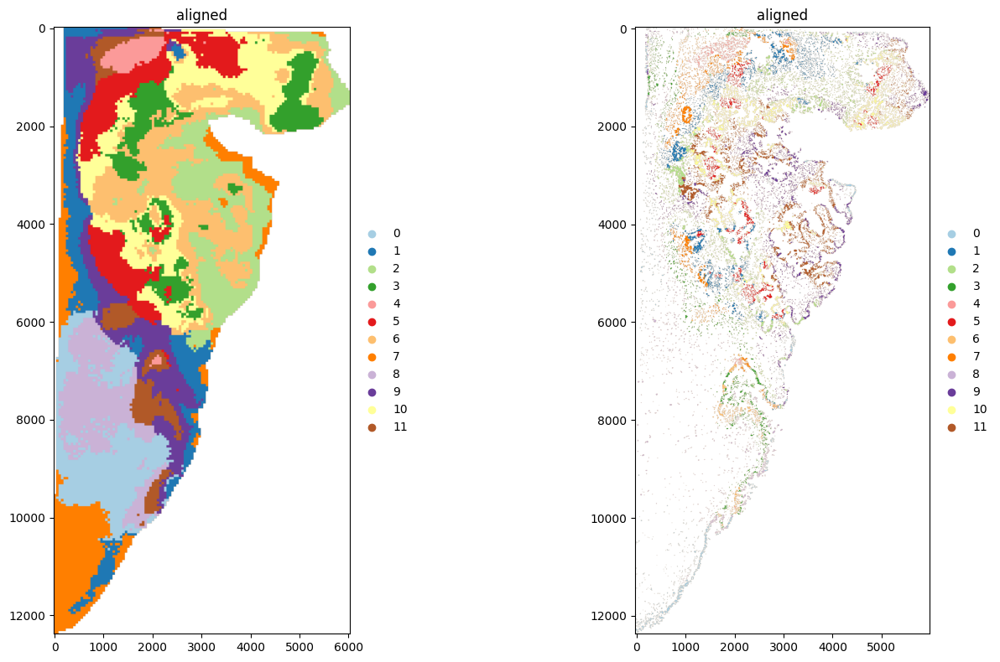

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), dpi=200)

sdata.pl.render_shapes("pixels", color="GPCA_clusters",cmap = "Paired", 
                       table_name="maldi_adata").pl.show(ax=axes[0], coordinate_systems="aligned")

sdata.pl.render_shapes("cell_segmentation", color="GPCA_clusters",cmap = "Paired", 
                       table_name="cell_adata").pl.show(ax=axes[1], coordinate_systems="aligned")


plt.tight_layout()
plt.show()

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 108 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/umap/spectral.py:548: UserWarnin

<Axes: title={'center': 'Clusters'}, xlabel='UMAP1', ylabel='UMAP2'>

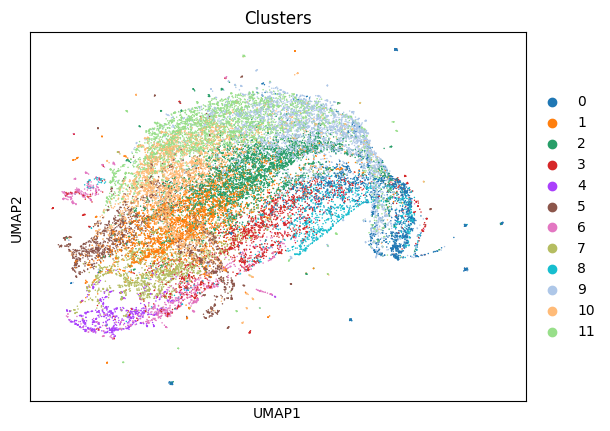

In [141]:
sc.pp.neighbors(sdata["cell_adata"], n_neighbors=15)
sc.tl.umap(sdata["cell_adata"])
sc.pl.umap(sdata["cell_adata"], color="GPCA_clusters",  show=False, title="Clusters")

/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `cell_segmentation` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:128: UserWarning: Key `cell_adata` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata_plot/pl/utils.py:800: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)
/Users/andrewcauser/anaconda3/envs/goatpy/lib/python3.10/site-packages/spatialdata/_core/_elements.py:108: UserWarning: Key `ce

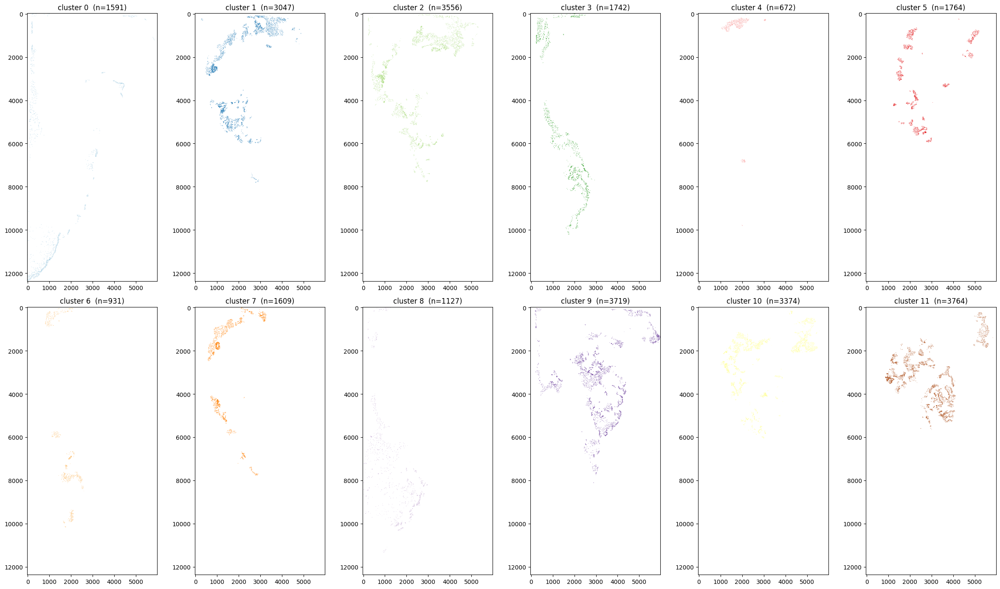

In [143]:
from matplotlib.colors import to_hex

adata = sdata["cell_adata"]
key = "GPCA_clusters"
adata.obs[key] = adata.obs[key].astype(str).astype("category")

# numeric order 0..11, stored on the data
clusters = sorted(adata.obs[key].cat.categories, key=lambda s: int(s) if s.isdigit() else s)
adata.obs[key] = adata.obs[key].cat.reorder_categories(clusters)

# Paired colours assigned in that same order
paired = [to_hex(c) for c in plt.get_cmap("Paired").colors]
color_of = dict(zip(clusters, paired))
adata.uns[f"{key}_colors"] = [color_of[c] for c in clusters]   # the full plot now uses these too

ncols = 6
nrows = int(np.ceil(len(clusters) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 7 * nrows), dpi=150)
axes = np.atleast_1d(axes).ravel()

for ax, c in zip(axes, clusters):
    col = adata.obs[key].where(adata.obs[key] == c)
    adata.obs["_highlight"] = col.cat.remove_unused_categories()

    (sdata.pl.render_shapes("cell_segmentation", color="_highlight",
                            groups=[c], palette=[color_of[c]], na_color="#f6eaeaff",
                            table_name="cell_adata")
          .pl.show(coordinate_systems="aligned", ax=ax))
    ax.set_title(f"cluster {c}  (n={int((adata.obs[key] == c).sum())})")
    if ax.get_legend() is not None:
        ax.get_legend().remove()

for ax in axes[len(clusters):]:
    ax.axis("off")

adata.obs.drop(columns="_highlight", inplace=True, errors="ignore")
plt.tight_layout()
plt.show()

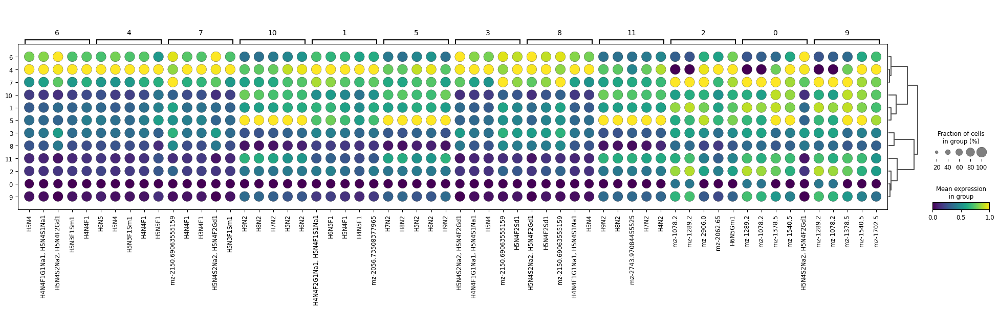

In [142]:
adata = sdata["cell_adata"]
key = "GPCA_clusters"

adata.obs[key] = adata.obs[key].astype(str).astype("category")

# drop stale entries computed under the old integer labels
adata.uns.pop(f"dendrogram_{key}", None)
adata.uns.pop(f"{key}_colors", None)
adata.uns.pop("rank_genes_groups", None)

sc.tl.rank_genes_groups(adata, groupby=key, method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(
    adata, n_genes=5, groupby=key,
    dendrogram=True,
    standard_scale="var", cmap="viridis",
)

## Tutorial Session Info

In [ ]:
from session_info import show
show()